# Bài 1: FFT, STFT, Mel-Spectrogram và MFCC

Notebook thực hiện đầy đủ yêu cầu trong `1.txt`:

1. So sánh FFT và STFT trên tín hiệu tổng hợp 440 Hz → 880 Hz.
2. Tự chia frame chồng lấp, áp dụng cửa sổ Hann và tính STFT bằng `np.fft.rfft()`.
3. Tính Magnitude, Power và dB Spectrogram với cửa sổ 10 ms, 25 ms và 50 ms.
4. Tạo Mel-Spectrogram, Log-Mel Spectrogram và 13 hệ số MFCC.
5. Đối chiếu STFT tự cài đặt với `librosa.stft()`.

File `audio/speech.wav` gồm hai từ **“no stop”** của cùng một người nói. “No” có nguyên âm kéo dài, còn “stop” chứa phụ âm bật /t/ và /p/.

In [1]:
import numpy as np
import librosa
import librosa.display
import matplotlib.pyplot as plt
from IPython.display import Audio, display

SAMPLE_RATE = 16000
AUDIO_PATH = 'audio/speech.wav'

print(f'Librosa version: {librosa.__version__}')
print(f'Sample rate sử dụng: {SAMPLE_RATE} Hz')

Librosa version: 1.0.0
Sample rate sử dụng: 16000 Hz


## 1. Hàm tự chia frame và tính STFT

In [2]:
def frame_signal(signal, frame_length, hop_length):
    if len(signal) < frame_length:
        signal = np.pad(signal, (0, frame_length - len(signal)))

    num_frames = 1 + (len(signal) - frame_length) // hop_length
    starts = np.arange(num_frames) * hop_length
    indices = starts[:, None] + np.arange(frame_length)[None, :]
    return signal[indices], starts


def manual_stft(signal, sr, frame_length, hop_length, n_fft=None):
    if n_fft is None:
        n_fft = frame_length

    frames, starts = frame_signal(signal, frame_length, hop_length)
    hann_window = np.hanning(frame_length)
    windowed_frames = frames * hann_window
    spectrum = np.fft.rfft(windowed_frames, n=n_fft, axis=1).T

    frequencies = np.fft.rfftfreq(n_fft, d=1 / sr)
    frame_times = (starts + frame_length / 2) / sr
    return spectrum, frequencies, frame_times


print('Đã định nghĩa hàm frame_signal() và manual_stft().')

Đã định nghĩa hàm frame_signal() và manual_stft().


## 2. So sánh FFT và STFT trên tín hiệu 440 Hz → 880 Hz

In [3]:
duration = 2.0
t = np.arange(int(SAMPLE_RATE * duration)) / SAMPLE_RATE
synthetic_signal = np.where(
    t < 1.0,
    np.sin(2 * np.pi * 440 * t),
    np.sin(2 * np.pi * 880 * t)
).astype(np.float32)

print('Giây 0–1: 440 Hz')
print('Giây 1–2: 880 Hz')
display(Audio(synthetic_signal, rate=SAMPLE_RATE))

Giây 0–1: 440 Hz
Giây 1–2: 880 Hz


D:\DuyToan\Python\DUT_AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


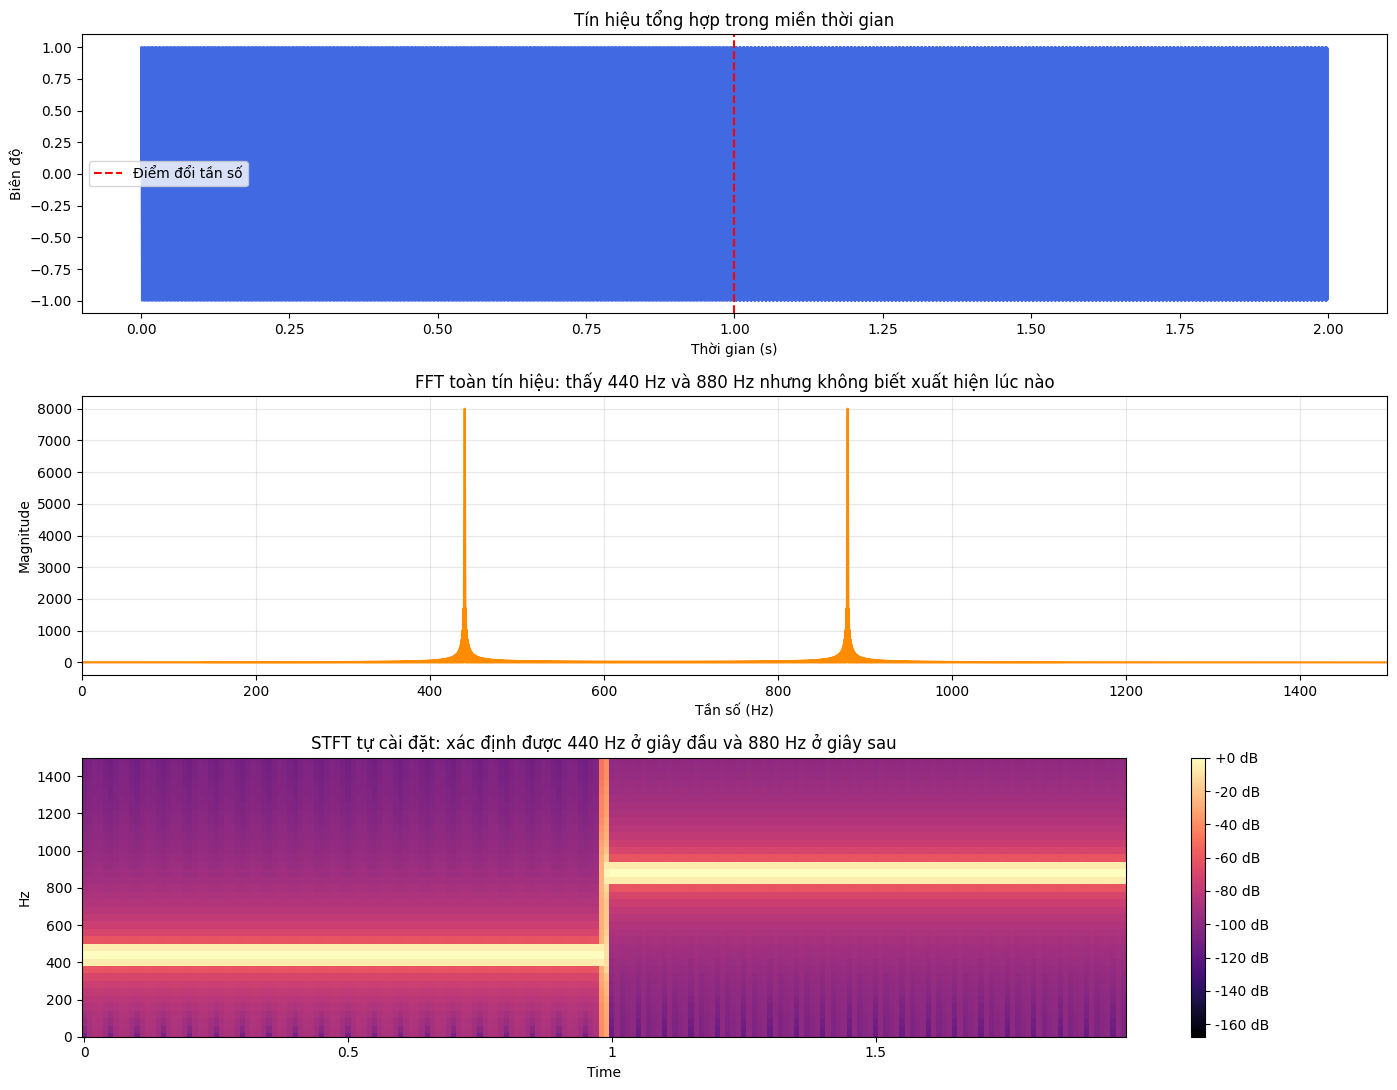

In [4]:
# FFT trên toàn bộ tín hiệu
fft_values = np.fft.rfft(synthetic_signal)
fft_magnitude = np.abs(fft_values)
fft_frequencies = np.fft.rfftfreq(len(synthetic_signal), d=1 / SAMPLE_RATE)

# STFT tự cài đặt với cửa sổ 25 ms, bước nhảy 10 ms
frame_length = int(0.025 * SAMPLE_RATE)
hop_length = int(0.010 * SAMPLE_RATE)
synthetic_stft, _, _ = manual_stft(
    synthetic_signal, SAMPLE_RATE, frame_length, hop_length
)
synthetic_db = 20 * np.log10(np.maximum(np.abs(synthetic_stft), 1e-10))
synthetic_db -= synthetic_db.max()

fig, axes = plt.subplots(3, 1, figsize=(14, 11))

axes[0].plot(t, synthetic_signal, color='royalblue')
axes[0].axvline(1.0, color='red', linestyle='--', label='Điểm đổi tần số')
axes[0].set_title('Tín hiệu tổng hợp trong miền thời gian')
axes[0].set_xlabel('Thời gian (s)')
axes[0].set_ylabel('Biên độ')
axes[0].legend()

axes[1].plot(fft_frequencies, fft_magnitude, color='darkorange')
axes[1].set_xlim(0, 1500)
axes[1].set_title('FFT toàn tín hiệu: thấy 440 Hz và 880 Hz nhưng không biết xuất hiện lúc nào')
axes[1].set_xlabel('Tần số (Hz)')
axes[1].set_ylabel('Magnitude')
axes[1].grid(alpha=0.3)

img = librosa.display.specshow(
    synthetic_db,
    sr=SAMPLE_RATE,
    hop_length=hop_length,
    n_fft=frame_length,
    x_axis='time',
    y_axis='hz',
    cmap='magma',
    ax=axes[2]
)
axes[2].set_ylim(0, 1500)
axes[2].set_title('STFT tự cài đặt: xác định được 440 Hz ở giây đầu và 880 Hz ở giây sau')
fig.colorbar(img, ax=axes[2], format='%+2.0f dB')

plt.tight_layout()
display(fig)
plt.close(fig)

## 3. Đọc và nghe file tiếng nói

In [5]:
y, sr = librosa.load(AUDIO_PATH, sr=SAMPLE_RATE, mono=True)
duration = len(y) / sr

print(f'File: {AUDIO_PATH}')
print(f'Sample rate: {sr} Hz')
print(f'Số sample: {len(y)}')
print(f'Thời lượng: {duration:.2f} giây')
display(Audio(y, rate=sr))

File: audio/speech.wav
Sample rate: 16000 Hz
Số sample: 35200
Thời lượng: 2.20 giây


## 4. Magnitude, Power và dB Spectrogram với 10/25/50 ms

In [6]:
window_sizes_ms = [10, 25, 50]
stft_results = {}

for window_ms in window_sizes_ms:
    frame_length = int(sr * window_ms / 1000)
    hop_length = frame_length // 2

    spectrum, frequencies, frame_times = manual_stft(
        y, sr, frame_length, hop_length
    )
    magnitude = np.abs(spectrum)
    power = magnitude ** 2
    db_spectrogram = 10 * np.log10(np.maximum(power, 1e-10))
    db_spectrogram -= db_spectrogram.max()

    stft_results[window_ms] = {
        'frame_length': frame_length,
        'hop_length': hop_length,
        'spectrum': spectrum,
        'magnitude': magnitude,
        'power': power,
        'db': db_spectrogram,
        'frequencies': frequencies,
        'times': frame_times,
    }

    print(
        f'{window_ms:2d} ms: frame={frame_length:3d} samples, '
        f'hop={hop_length:3d}, frames={magnitude.shape[1]:3d}, '
        f'bins={magnitude.shape[0]:3d}, Δf≈{sr / frame_length:.1f} Hz'
    )

example = stft_results[25]
print(f"\nMagnitude shape: {example['magnitude'].shape}")
print(f"Power shape: {example['power'].shape}")
print(f"dB Spectrogram range: {example['db'].min():.1f} đến {example['db'].max():.1f} dB")

10 ms: frame=160 samples, hop= 80, frames=439, bins= 81, Δf≈100.0 Hz
25 ms: frame=400 samples, hop=200, frames=175, bins=201, Δf≈40.0 Hz
50 ms: frame=800 samples, hop=400, frames= 87, bins=401, Δf≈20.0 Hz

Magnitude shape: (201, 175)
Power shape: (201, 175)
dB Spectrogram range: -135.9 đến 0.0 dB


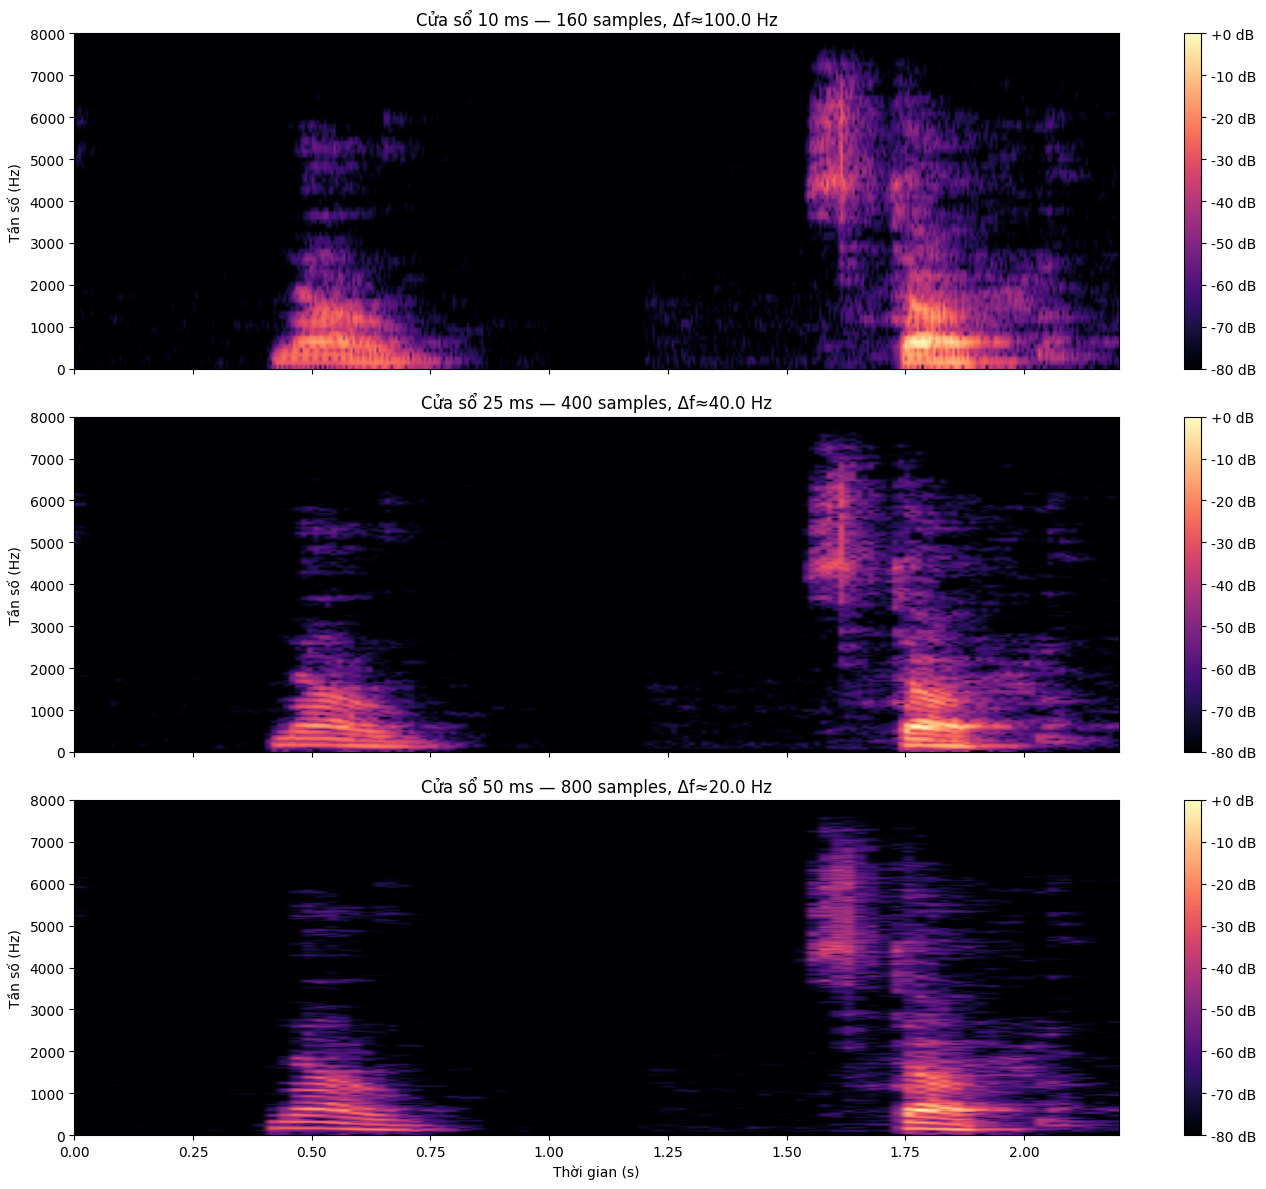

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12), sharex=True)

for ax, window_ms in zip(axes, window_sizes_ms):
    result = stft_results[window_ms]
    image = ax.imshow(
        result['db'],
        origin='lower',
        aspect='auto',
        extent=[0, duration, 0, sr / 2],
        cmap='magma',
        vmin=-80,
        vmax=0
    )
    ax.set_ylim(0, 8000)
    ax.set_ylabel('Tần số (Hz)')
    ax.set_title(
        f'Cửa sổ {window_ms} ms — '
        f'{result["frame_length"]} samples, '
        f'Δf≈{sr / result["frame_length"]:.1f} Hz'
    )
    fig.colorbar(image, ax=ax, format='%+2.0f dB')

axes[-1].set_xlabel('Thời gian (s)')
plt.tight_layout()
display(fig)
plt.close(fig)

## 5. Waveform → Spectrogram → Log-Mel Spectrogram → MFCC

Mel-Spectrogram shape: (64, 221)
Log-Mel Spectrogram shape: (64, 221)
MFCC shape: (13, 221)


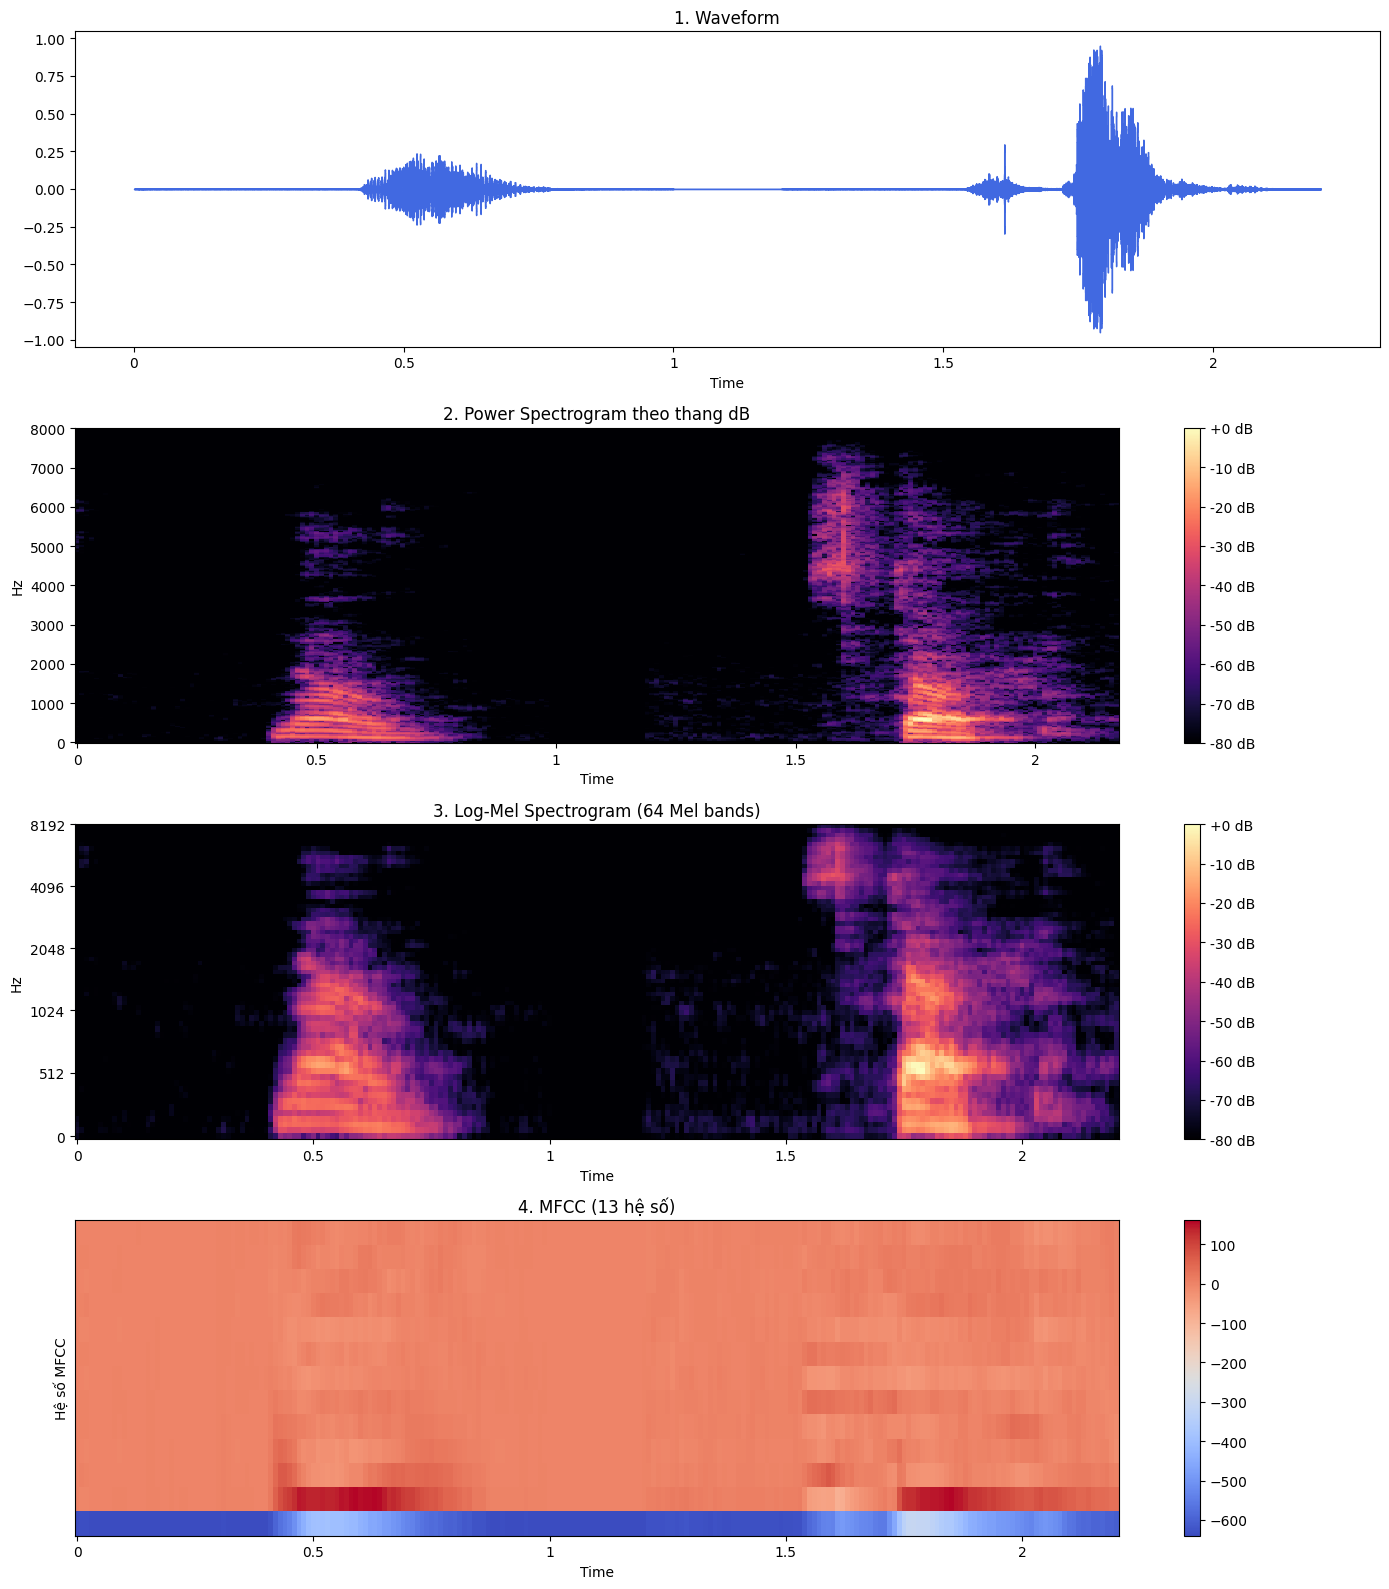

In [8]:
n_fft = 512
win_length = int(0.025 * sr)
hop_length = int(0.010 * sr)

speech_stft, _, _ = manual_stft(y, sr, win_length, hop_length, n_fft=n_fft)
speech_power = np.abs(speech_stft) ** 2
speech_db = librosa.power_to_db(speech_power, ref=np.max)

mel_spectrogram = librosa.feature.melspectrogram(
    y=y,
    sr=sr,
    n_fft=n_fft,
    win_length=win_length,
    hop_length=hop_length,
    n_mels=64,
    power=2.0
)
log_mel = librosa.power_to_db(mel_spectrogram, ref=np.max)
mfcc = librosa.feature.mfcc(S=log_mel, n_mfcc=13)

print(f'Mel-Spectrogram shape: {mel_spectrogram.shape}')
print(f'Log-Mel Spectrogram shape: {log_mel.shape}')
print(f'MFCC shape: {mfcc.shape}')

fig, axes = plt.subplots(4, 1, figsize=(14, 16))

librosa.display.waveshow(y, sr=sr, ax=axes[0], color='royalblue')
axes[0].set_title('1. Waveform')

img1 = librosa.display.specshow(
    speech_db, sr=sr, hop_length=hop_length, n_fft=n_fft,
    x_axis='time', y_axis='hz', cmap='magma', ax=axes[1]
)
axes[1].set_title('2. Power Spectrogram theo thang dB')
fig.colorbar(img1, ax=axes[1], format='%+2.0f dB')

img2 = librosa.display.specshow(
    log_mel, sr=sr, hop_length=hop_length,
    x_axis='time', y_axis='mel', cmap='magma', ax=axes[2]
)
axes[2].set_title('3. Log-Mel Spectrogram (64 Mel bands)')
fig.colorbar(img2, ax=axes[2], format='%+2.0f dB')

img3 = librosa.display.specshow(
    mfcc, sr=sr, hop_length=hop_length,
    x_axis='time', cmap='coolwarm', ax=axes[3]
)
axes[3].set_title('4. MFCC (13 hệ số)')
axes[3].set_ylabel('Hệ số MFCC')
fig.colorbar(img3, ax=axes[3])

plt.tight_layout()
display(fig)
plt.close(fig)

## 6. Đối chiếu STFT tự cài đặt và `librosa.stft()`

Shape STFT tự cài đặt: (201, 218)
Shape librosa.stft:    (201, 218)
Sai khác tuyệt đối lớn nhất: 0.00000333
Sai khác tuyệt đối trung bình: 0.00000000


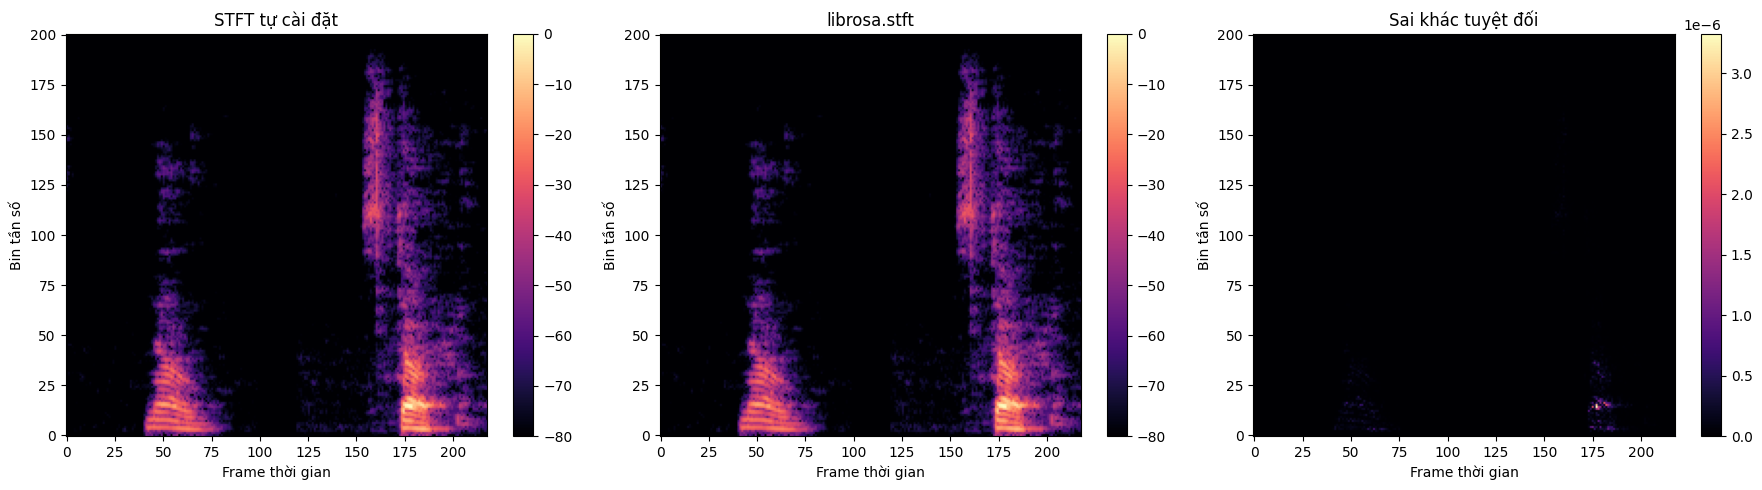

In [9]:
frame_length = int(0.025 * sr)
hop_length = int(0.010 * sr)
hann_window = np.hanning(frame_length)

manual_spectrum, _, _ = manual_stft(
    y, sr, frame_length, hop_length, n_fft=frame_length
)
librosa_spectrum = librosa.stft(
    y,
    n_fft=frame_length,
    hop_length=hop_length,
    win_length=frame_length,
    window=hann_window,
    center=False
)

manual_magnitude = np.abs(manual_spectrum)
librosa_magnitude = np.abs(librosa_spectrum)
absolute_difference = np.abs(manual_magnitude - librosa_magnitude)

print(f'Shape STFT tự cài đặt: {manual_spectrum.shape}')
print(f'Shape librosa.stft:    {librosa_spectrum.shape}')
print(f'Sai khác tuyệt đối lớn nhất: {absolute_difference.max():.8f}')
print(f'Sai khác tuyệt đối trung bình: {absolute_difference.mean():.8f}')

manual_db = librosa.amplitude_to_db(manual_magnitude, ref=np.max)
librosa_db = librosa.amplitude_to_db(librosa_magnitude, ref=np.max)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, data, title in [
    (axes[0], manual_db, 'STFT tự cài đặt'),
    (axes[1], librosa_db, 'librosa.stft'),
    (axes[2], absolute_difference, 'Sai khác tuyệt đối'),
]:
    image = ax.imshow(data, origin='lower', aspect='auto', cmap='magma')
    ax.set_title(title)
    ax.set_xlabel('Frame thời gian')
    ax.set_ylabel('Bin tần số')
    fig.colorbar(image, ax=ax)

plt.tight_layout()
display(fig)
plt.close(fig)

## 7. Nhận xét

- **FFT** phát hiện tín hiệu có hai thành phần 440 Hz và 880 Hz, nhưng vì xử lý toàn bộ 2 giây cùng lúc nên không thể cho biết tần số nào xuất hiện trước.
- **STFT** chia tín hiệu thành nhiều đoạn ngắn nên giữ được cả thông tin thời gian và tần số.
- Cửa sổ **10 ms** tạo nhiều frame, theo dõi thay đổi nhanh tốt nhưng các dải tần rộng và khó tách chi tiết.
- Cửa sổ **50 ms** phân biệt tần số tốt hơn nhưng làm mờ thời điểm thay đổi. Cửa sổ **25 ms** là lựa chọn cân bằng thường dùng cho tiếng nói.
- Mel-Spectrogram nén trục tần số theo cách gần với thính giác người. Log-Mel nén dải động, còn MFCC tiếp tục cô đọng bao phổ thành 13 hệ số.
- Hai kết quả STFT gần như trùng nhau vì dùng cùng frame, hop, Hann window, `n_fft` và đều không padding ở hai đầu.